# 06. Nested CV, ROC và độ ổn định đặc trưng

Outer **Stratified 6-Fold, seed 42, theo participant** giữ nguyên baseline.
Trong mỗi outer train, inner 3-fold chọn reducer, mức chiều và classifier.
Đối chứng `baseline` cũng chọn classifier trong inner CV nhưng không giảm chiều.

Notebook này đánh giá **quy trình chọn cấu hình**, không xác nhận riêng cấu hình
thắng bảng 05. Không huấn luyện lại hoặc chọn threshold từ dự đoán test.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.float_format', '{:.6f}'.format)

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
OUT = ROOT / 'results/feature_optimization'
validation = json.loads((OUT / 'validation.json').read_text(encoding='utf-8'))
assert validation['complete'], 'Hoàn tất và validate thực nghiệm trước khi xem.'
summary = pd.read_csv(OUT / 'summary.csv')
BRANCHES = ['Kinematic', 'MOMENT', 'GAF', 'CWT']
METRICS = [('accuracy', 'Accuracy'), ('f1_macro', 'F1 macro'), ('auc', 'ROC-AUC')]
COLORS = {'none':'#555555', 'pca':'#0072B2', 'anova':'#D55E00', 'extratrees':'#009E73'}
FIG = OUT / 'figures'
FIG.mkdir(exist_ok=True)
exports = []
plt.rcParams.update({'font.size':10, 'axes.spines.top':False,
                     'axes.spines.right':False, 'svg.fonttype':'none'})

def show(fig, name, description, sources):
    for ext in ('png', 'svg'):
        fig.savefig(FIG / f'{name}.{ext}', dpi=180, facecolor='white')
    exports.append(dict(name=name, description=description, sources=sources,
                        formats=['png','svg'], n_participants=258,
                        uncertainty='Fold SD where shown; not a confidence interval'))
    plt.show()
    plt.close(fig)

def save_manifest(name):
    for item in exports:
        item['source_sha256']={p:hashlib.sha256((OUT/p).read_bytes()).hexdigest()
                               for p in item['sources']}
    (FIG / name).write_text(json.dumps(exports, ensure_ascii=False, indent=2), encoding='utf-8')

print('Project:', ROOT)
print('Validated configurations:', len(summary), '| Participants: 258 | Outer folds: 6 | Seed: 42')

Project: E:\DiaGraMo-project
Validated configurations: 216 | Participants: 258 | Outer folds: 6 | Seed: 42


## Kết quả cuối cùng dạng số — nested CV

Ưu tiên bảng này khi kết luận về **quy trình tối ưu**. Metric giữ thang 0–1,
tách rõ OOF gộp, trung bình và SD qua 6 outer fold. `baseline` và `optimized`
đều chọn cấu hình bằng inner CV, không dùng outer test để chọn.

In [2]:
nested_final = pd.read_csv(OUT / 'nested_summary.csv')
numeric_columns = ['branch','scenario','raw_features','mean_features',
                   'accuracy','f1_macro','f1_weighted','f1_binary','auc','balanced_accuracy',
                   'mean_accuracy','mean_f1_macro','mean_auc',
                   'std_accuracy','std_f1_macro','std_auc']
nested_final[numeric_columns].sort_values(['branch','scenario']).reset_index(drop=True)

,branch,scenario,raw_features,mean_features,accuracy,f1_macro,f1_weighted,f1_binary,auc,balanced_accuracy,mean_accuracy,mean_f1_macro,mean_auc,std_accuracy,std_f1_macro,std_auc
0,CWT,baseline,25088,25088.000000,0.686047,0.683953,0.686744,0.709677,0.755488,0.685284,0.686047,0.681032,0.758514,0.061967,0.064865,0.063031
1,CWT,optimized,25088,216.666667,0.658915,0.653586,0.658249,0.696552,0.702159,0.653147,0.658915,0.647895,0.704500,0.068463,0.071140,0.056932
2,GAF,baseline,10752,10752.000000,0.624031,0.612234,0.619575,0.679868,0.648951,0.612314,0.624031,0.609513,0.662659,0.053875,0.047300,0.071636
3,GAF,optimized,10752,133.333333,0.565891,0.558219,0.564538,0.616438,0.579021,0.558164,0.565891,0.552789,0.610460,0.086600,0.078256,0.093959
4,Kinematic,baseline,1036,1027.666667,0.802326,0.800137,0.802407,0.821053,0.869322,0.800395,0.802326,0.799981,0.874787,0.093891,0.093212,0.051417
5,Kinematic,optimized,1036,444.333333,0.790698,0.789165,0.791116,0.807143,0.847917,0.790757,0.790698,0.788298,0.854319,0.053031,0.054192,0.072833
6,MOMENT,baseline,14336,14336.000000,0.651163,0.635181,0.643468,0.711538,0.665035,0.635938,0.651163,0.634695,0.701057,0.055033,0.054715,0.081770
7,MOMENT,optimized,14336,225.333333,0.670543,0.665717,0.670076,0.705882,0.708544,0.665339,0.670543,0.661772,0.715971,0.037258,0.038368,0.036902


## Baseline → tối ưu và chênh lệch

Cột `baseline_*` và `optimized_*` là mean metric qua 6 fold, thang 0–1.
Cột `delta_*_pp` là chênh lệch điểm phần trăm.

In [3]:
nested_comparison_numbers = pd.read_csv(OUT / 'nested_comparison.csv')
nested_comparison_numbers.set_index('branch').loc[BRANCHES].reset_index()

,branch,mean_features,baseline_accuracy,baseline_f1_macro,baseline_auc,optimized_accuracy,optimized_f1_macro,optimized_auc,delta_accuracy_pp,delta_f1_macro_pp,delta_auc_pp
0,Kinematic,444.333333,0.802326,0.799981,0.874787,0.790698,0.788298,0.854319,-1.162791,-1.168302,-2.046784
1,MOMENT,225.333333,0.651163,0.634695,0.701057,0.670543,0.661772,0.715971,1.937984,2.707731,1.491387
2,GAF,133.333333,0.624031,0.609513,0.662659,0.565891,0.552789,0.610460,-5.813953,-5.672361,-5.219934
3,CWT,216.666667,0.686047,0.681032,0.758514,0.658915,0.647895,0.704500,-2.713178,-3.313739,-5.401411


In [4]:
nested = pd.read_csv(OUT / 'nested_summary.csv')
compare = pd.read_csv(OUT / 'nested_comparison.csv').set_index('branch').loc[BRANCHES]
choices = pd.read_csv(OUT / 'selected_by_fold.csv')
oof = pd.read_csv(OUT / 'nested_oof.csv')
stability = pd.read_csv(OUT / 'feature_stability.csv')
display(compare.round(4))

,mean_features,baseline_accuracy,baseline_f1_macro,baseline_auc,optimized_accuracy,optimized_f1_macro,optimized_auc,delta_accuracy_pp,delta_f1_macro_pp,delta_auc_pp
branch,,,,,,,,,,
Kinematic,444.333300,0.802300,0.800000,0.874800,0.790700,0.788300,0.854300,-1.162800,-1.168300,-2.046800
MOMENT,225.333300,0.651200,0.634700,0.701100,0.670500,0.661800,0.716000,1.938000,2.707700,1.491400
GAF,133.333300,0.624000,0.609500,0.662700,0.565900,0.552800,0.610500,-5.814000,-5.672400,-5.219900
CWT,216.666700,0.686000,0.681000,0.758500,0.658900,0.647900,0.704500,-2.713200,-3.313700,-5.401400


## Quy trình tối ưu so với quy trình baseline

Mean ± SD của 6 outer fold; cả hai quy trình dùng cùng participant test.
SD không phải CI và các tập train chồng lấp, không dùng kiểm định độc lập trên 6 fold.

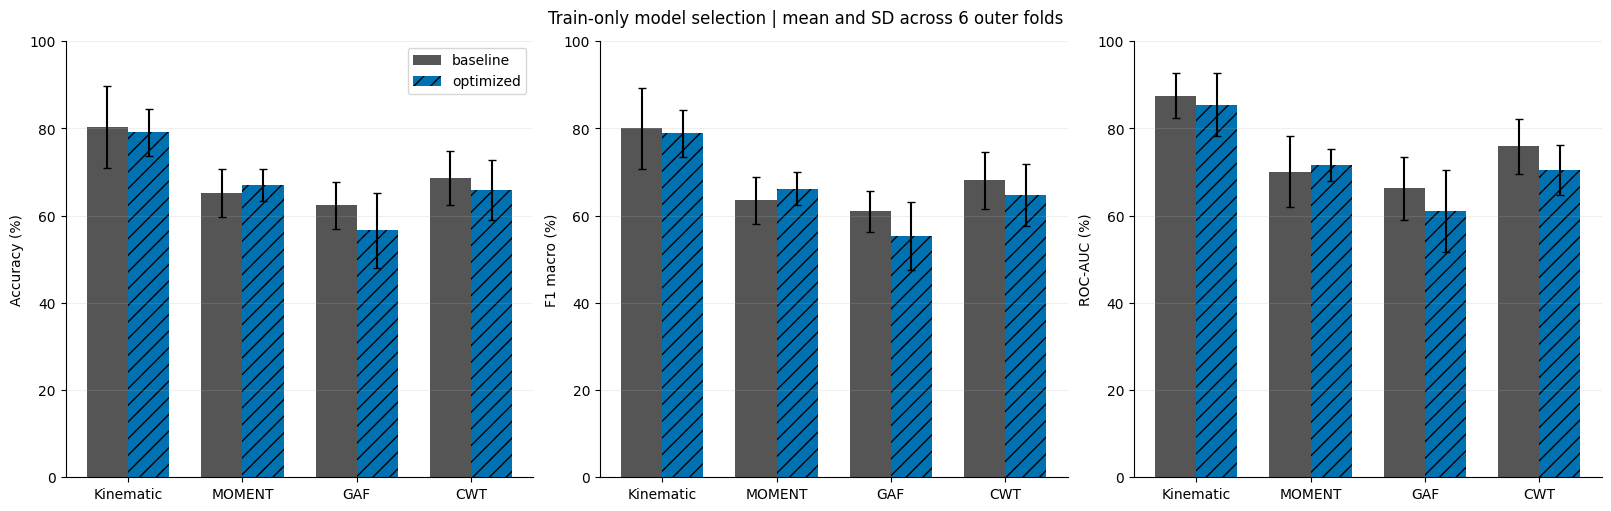

In [5]:
fig, axes = plt.subplots(1,3,figsize=(16,5),layout='constrained')
x = np.arange(4)
for ax,(m,label) in zip(axes,METRICS):
    for offset,scenario,color,hatch in [(-.18,'baseline','#555555',''),(.18,'optimized','#0072B2','//')]:
        g = nested[nested.scenario==scenario].set_index('branch').loc[BRANCHES]
        ax.bar(x+offset,100*g['mean_'+m],.36,yerr=100*g['std_'+m],
               color=color,hatch=hatch,capsize=3,label=scenario)
    ax.set(xticks=x,xticklabels=BRANCHES,ylim=(0,100),ylabel=label+' (%)')
    ax.grid(axis='y',alpha=.2)
axes[0].legend()
fig.suptitle('Train-only model selection | mean and SD across 6 outer folds')
show(fig,'nested_comparison','Nested baseline versus optimized procedure; three metrics with outer-fold SD.', ['nested_summary.csv'])

## Chênh lệch từng fold và cấu hình được chọn

Mỗi điểm là (optimized − baseline) trên cùng outer test fold, đơn vị điểm phần trăm.
Bảng bên dưới giữ tên reducer và classifier của cả 6 fold để thấy độ ổn định lựa chọn.

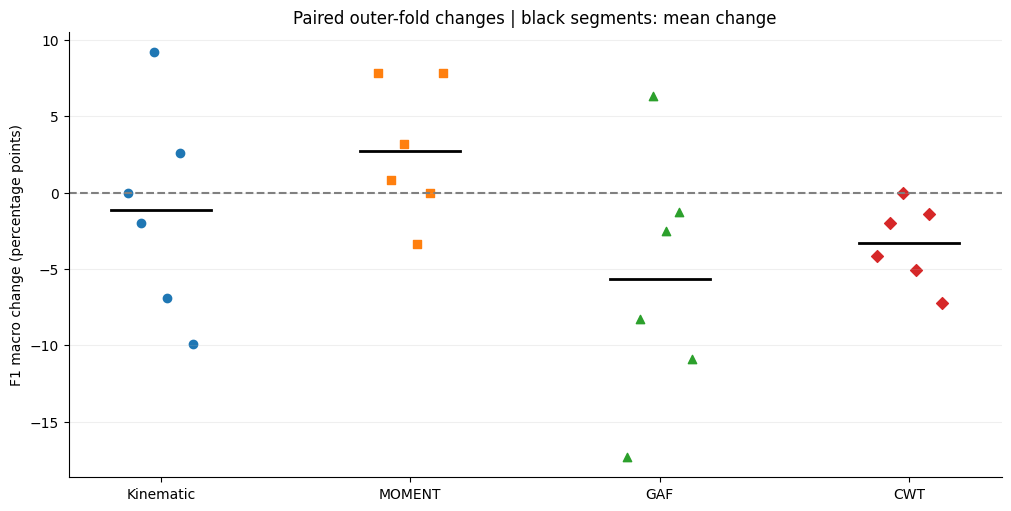

fold,0,1,2,3,4,5
branch,,,,,,
Kinematic,none / LightGBM,anova_512 / LogisticRegression,extratrees_256 / LogisticRegression,anova_512 / LightGBM,pca_var90 / LogisticRegression,extratrees_256 / LogisticRegression
MOMENT,anova_512 / SVM,anova_128 / LightGBM,anova_512 / LogisticRegression,pca_16 / LogisticRegression,pca_16 / LogisticRegression,pca_var95 / SVM
GAF,extratrees_128 / LogisticRegression,pca_16 / LogisticRegression,extratrees_64 / SVM,anova_512 / SVM,pca_16 / LogisticRegression,anova_64 / SVM
CWT,pca_128 / SVM,pca_32 / LogisticRegression,pca_var99 / LogisticRegression,anova_256 / LogisticRegression,pca_var95 / LogisticRegression,anova_512 / SVM


In [6]:
fig, ax = plt.subplots(figsize=(10,5),layout='constrained')
for i,branch in enumerate(BRANCHES):
    g = choices[choices.branch==branch].pivot(index='fold',columns='scenario',values='outer_f1_macro')
    delta = 100*(g.optimized-g.baseline)
    ax.scatter(i+np.linspace(-.13,.13,6),delta,label=branch,marker=['o','s','^','D'][i])
    ax.plot([i-.2,i+.2],[delta.mean()]*2,color='black',lw=2)
ax.axhline(0,color='gray',ls='--')
ax.set(xticks=range(4),xticklabels=BRANCHES,ylabel='F1 macro change (percentage points)',
       title='Paired outer-fold changes | black segments: mean change')
ax.grid(axis='y',alpha=.2)
show(fig,'nested_fold_changes','Each point is a paired fold F1 difference; no inference or confidence intervals.', ['selected_by_fold.csv'])
chosen = choices[choices.scenario=='optimized'].copy()
chosen['configuration'] = chosen.reducer+' / '+chosen.classifier
display(chosen.pivot(index='branch',columns='fold',values='configuration').reindex(BRANCHES))

## ROC từ dự đoán outer OOF

Mỗi đường gộp 258 dự đoán ngoài train. AUC hiển thị là **pooled OOF AUC**,
có thể khác mean AUC của 6 fold. Với nested CV, classifier có thể đổi giữa fold,
nên độ hiệu chỉnh xác suất giữa fold cũng có thể khác nhau.

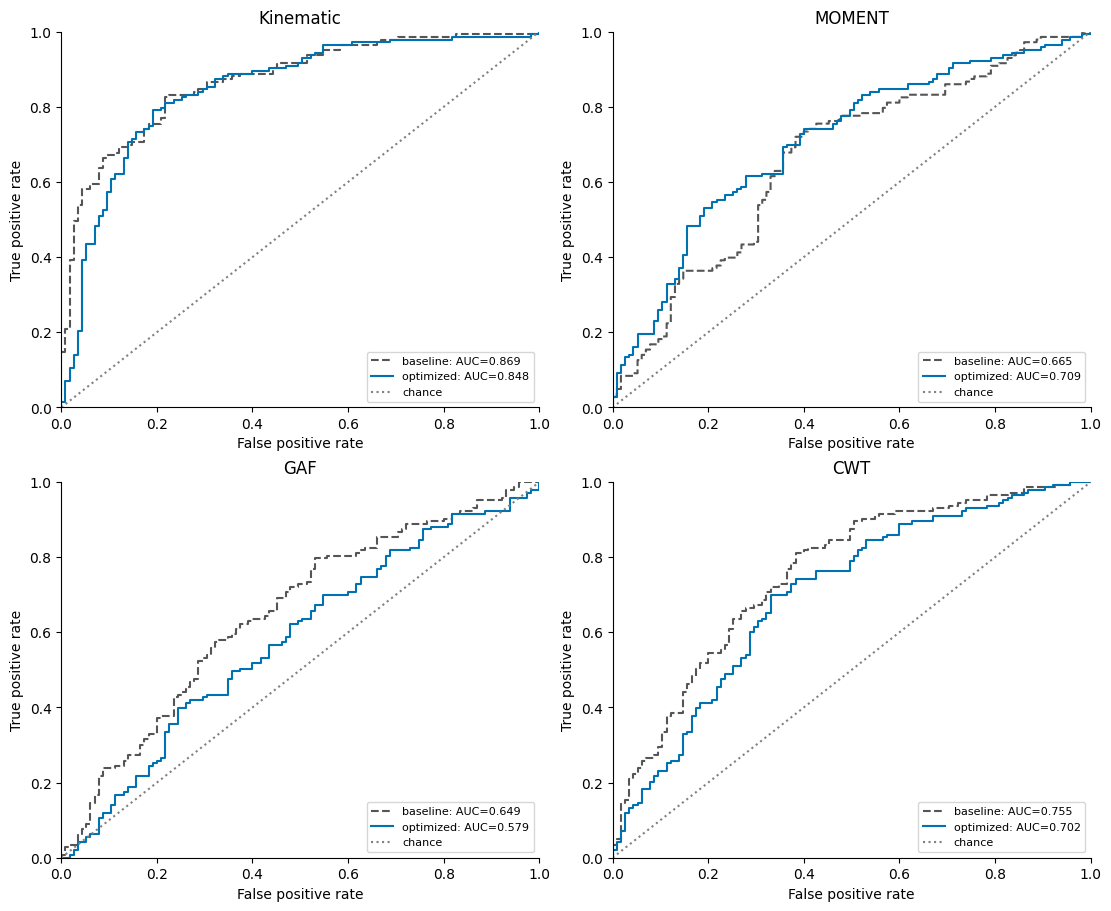

In [7]:
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
fig, axes = plt.subplots(2,2,figsize=(11,9),layout='constrained')
for ax,branch in zip(axes.flat,BRANCHES):
    for scenario,color,style in [('baseline','#555555','--'),('optimized','#0072B2','-')]:
        d = oof[(oof.branch==branch)&(oof.scenario==scenario)]
        assert len(d)==258 and d.participant_id.is_unique
        assert d.probability.between(0,1).all()
        fpr,tpr,_ = roc_curve(d.label,d.probability)
        auc = roc_auc_score(d.label,d.probability)
        ax.plot(fpr,tpr,color=color,ls=style,label=f'{scenario}: AUC={auc:.3f}')
    ax.plot([0,1],[0,1],color='gray',ls=':',label='chance')
    ax.set(title=branch,xlim=(0,1),ylim=(0,1),xlabel='False positive rate',ylabel='True positive rate')
    ax.legend(loc='lower right',fontsize=8)
show(fig,'nested_roc','Pooled outer OOF ROC of both train-selected procedures; AUC is pooled, not mean fold AUC.', ['nested_oof.csv'])

## Confusion matrix — giữ nguyên dự đoán đã lưu

Hiển thị số người, cùng thang màu cho cả 8 panel. Nhãn là trường `group` 0/1
của dataset; không đổi sang cờ chẩn đoán dysgraphia. Không tối ưu ngưỡng ở đây.

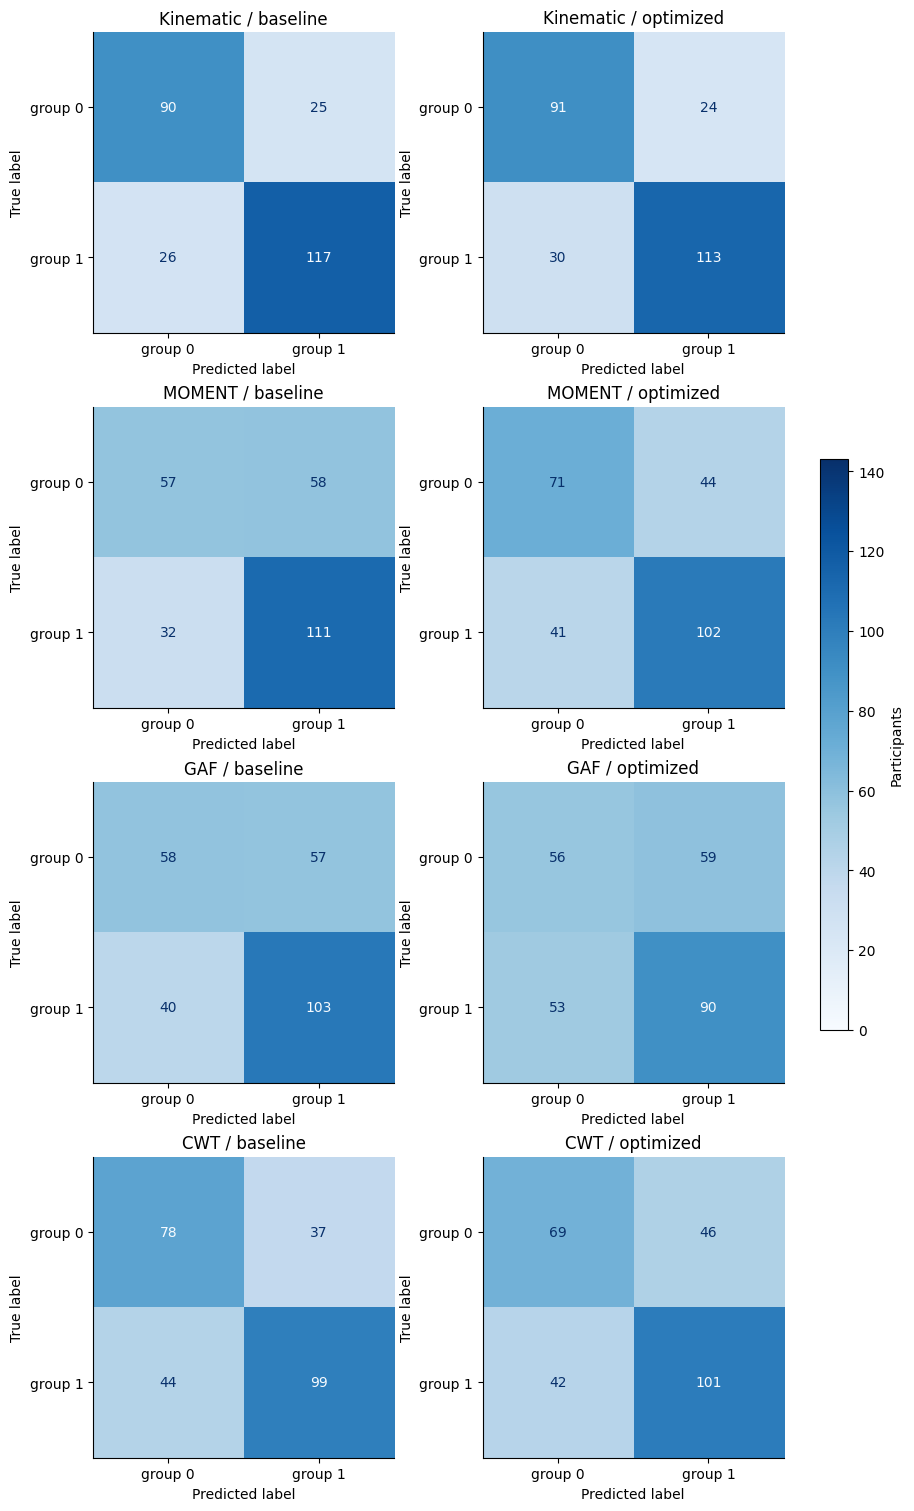

In [8]:
fig, axes = plt.subplots(4,2,figsize=(9,15),layout='constrained')
for i,branch in enumerate(BRANCHES):
    for j,scenario in enumerate(['baseline','optimized']):
        d = oof[(oof.branch==branch)&(oof.scenario==scenario)]
        cm = confusion_matrix(d.label,d.prediction,labels=[0,1])
        disp = ConfusionMatrixDisplay(cm,display_labels=['group 0','group 1'])
        disp.plot(ax=axes[i,j],colorbar=False,cmap='Blues',values_format='d',im_kw={'vmin':0,'vmax':143})
        axes[i,j].set_title(branch+' / '+scenario)
fig.colorbar(disp.im_,ax=axes,label='Participants',shrink=.4)
show(fig,'nested_confusion','Counts from stored predictions, shared 0–143 color scale; no threshold tuning.', ['nested_oof.csv'])

## Độ ổn định selector và phương sai PCA

Jaccard là trung bình trên 15 cặp tập đặc trưng của 6 outer train fold.
Các tập train chồng lấp nên đây là chỉ báo mô tả, không phải độ tái lập độc lập.
PCA bên dưới chỉ dùng phương sai đã fit trong outer train; không fit PCA trên toàn cohort.

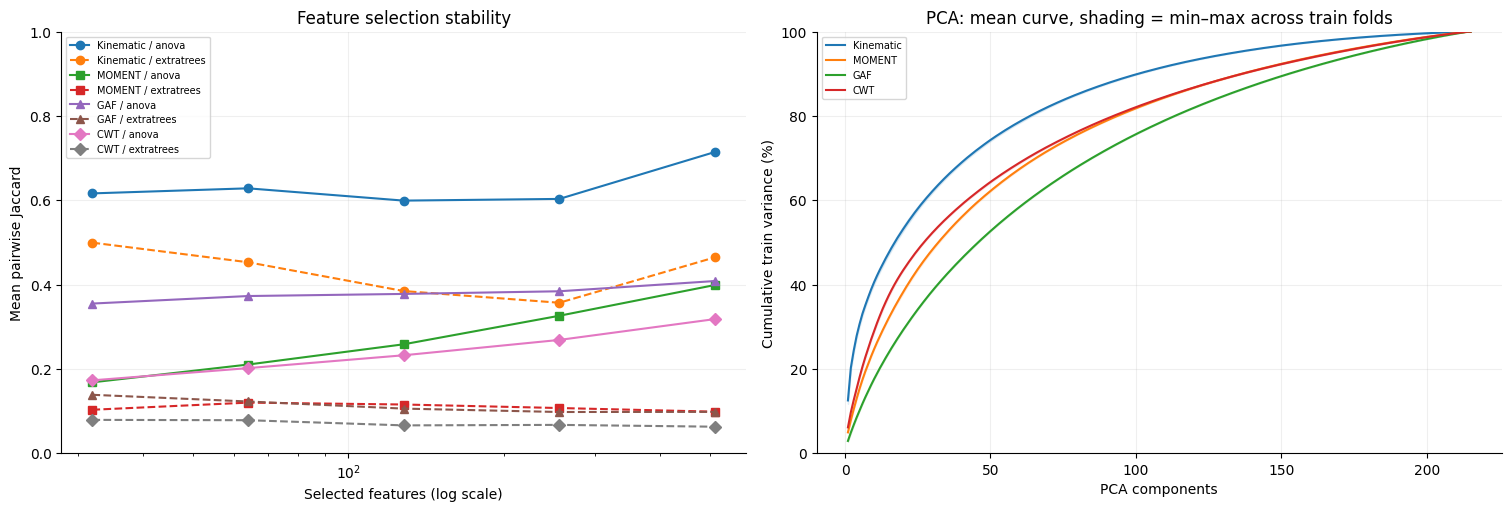

,branch,reducer,mean_pairwise_jaccard,n_features
0,Kinematic,anova_32,0.616000,32.000000
1,Kinematic,anova_64,0.628000,64.000000
2,Kinematic,anova_128,0.599000,128.000000
3,Kinematic,anova_256,0.603000,256.000000
4,Kinematic,anova_512,0.715000,512.000000
5,Kinematic,extratrees_32,0.499000,32.000000
6,Kinematic,extratrees_64,0.453000,64.000000
7,Kinematic,extratrees_128,0.385000,128.000000
8,Kinematic,extratrees_256,0.357000,256.000000
9,Kinematic,extratrees_512,0.465000,512.000000


In [9]:
fig, axes = plt.subplots(1,2,figsize=(15,5),layout='constrained')
for i,branch in enumerate(BRANCHES):
    for method,style in [('anova','-'),('extratrees','--')]:
        d = stability[(stability.branch==branch)&stability.reducer.str.startswith(method)].sort_values('n_features')
        axes[0].plot(d.n_features,d.mean_pairwise_jaccard,ls=style,marker=['o','s','^','D'][i],label=branch+' / '+method)
    curves = []
    for fold in range(6):
        record = json.loads((OUT/'folds'/f'{branch}__fold_{fold}.json').read_text())
        curves.append(np.cumsum(record['bank']['pca_explained_variance_ratio']))
    curves = np.array(curves)
    line, = axes[1].plot(np.arange(1,curves.shape[1]+1),100*curves.mean(axis=0),label=branch)
    axes[1].fill_between(np.arange(1,curves.shape[1]+1),100*curves.min(axis=0),
                         100*curves.max(axis=0),color=line.get_color(),alpha=.12)
axes[0].set(xscale='log',ylim=(0,1),xlabel='Selected features (log scale)',
            ylabel='Mean pairwise Jaccard',title='Feature selection stability')
axes[1].set(ylim=(0,100),xlabel='PCA components',ylabel='Cumulative train variance (%)',
            title='PCA: mean curve, shading = min–max across train folds')
for ax in axes:
    ax.grid(alpha=.2); ax.legend(fontsize=7)
show(fig,'stability_and_variance','Selector Jaccard and fold-local cumulative PCA variance; shading is fold range, not CI.',
     ['feature_stability.csv']+[f'folds/{b}__fold_{f}.json' for b in BRANCHES for f in range(6)])
display(stability.round(3))
save_manifest('nested_manifest.json')

## Cách đọc kết quả

- Kinematic: giảm chiều chưa tăng F1; giữ baseline nếu ưu tiên F1.
- MOMENT: quy trình tối ưu tăng F1 nested; tiếp tục kiểm chứng, chưa khẳng định riêng ANOVA-64 tối ưu.
- GAF/CWT: ứng viên thắng bảng thăm dò chưa giữ được lợi ích trong nested CV.
- Những giải thích về loại nhiễu/dư thừa là giả thuyết, chưa được xác nhận bằng ablation.

Chi tiết: `results/feature_optimization/REPORT_VI.md`. PNG/SVG và manifest nguồn
nằm trong `results/feature_optimization/figures/`. Không thay kết quả CV hoặc notebook cũ.